# Встреча 5. Где обычный A/B ломается: практика

> **Время:** 55 минут · **Опирается на:** `theory.ipynb` · **Данные:** `../data/store_panel.csv`

**Легенда.** Сеть из 300 магазинов у дома: 6 регионов, 3 формата, недельная выручка и трафик с января 2024 года по июнь 2025-го. Осенью 2024 года сеть открыла бьюти-зону с консультантом. Рандомизации не было: директор по рознице сам выбрал 60 «сильных» магазинов. Зона работала 12 недель, с 7 октября по 29 декабря 2024 года.

Директор принёс отчёт: «Выручка выросла почти на 6% относительно остальной сети, интервал далеко от нуля». Зона окупается, если выручка растёт хотя бы на **4.5%** (допущение легенды: аренда места, консультант, товарный запас). От вас — честная оценка эффекта и ответ, окупается ли зона.

По пути разберём, где обычный A/B ломается: зависимые наблюдения, мощность без формулы, неслучайный отбор. В конце — короткое задание про switchback, где ломается уже SUTVA.

| № | Задание | Минут |
| :---: | --- | :---: |
| 1 | ICC и A/A на разных единицах: цена неверной единицы анализа | 12 |
| 2 | Мощность инъекцией эффекта по истории | 10 |
| 3 | Наивный DiD на волне директора и плацебо по датам | 10 |
| 4 | Пары и DiD по парам: что лечит матчинг и что нет | 13 |
| 5 | Switchback: окно и A/A по эпохам | 10 |

Формат: задание → ячейка `# ВАШ КОД` → свёрнутое решение → ячейка «Проверка» с `assert`.

* **Свой код проверяйте так:** запустите свою ячейку, затем сразу «Проверку», пропустив ячейку решения.
* **Решение перезаписывает ваши переменные и функции.** Поэтому не нажимайте Run All, если проверяете своё: он выполнит решения поверх вашего кода. На незаполненной заглушке Run All остановится с `NotImplementedError`.
* **Застряли больше 5 минут** — запустите решение: дальше ноутбук опирается на его переменные.

## 0. Подготовка

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import nnls
from scipy.signal import lfilter

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'
DATA = Path('../data/store_panel.csv')

SEED = 2027
ALPHA, POWER = 0.05, 0.80
Z_SUM = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER)   # ≈ 2.80
PRE, POST = 12, 12                  # недель до пилота и недель пилота
PILOT_START = pd.Timestamp('2024-10-07')
BREAKEVEN = 0.045                   # допущение легенды: зона окупается при +4.5% выручки

Панель «магазин × неделя». Список магазинов директора — из его же отчёта; в данных пометки нет.

In [2]:
panel = pd.read_csv(DATA, parse_dates=['week'])
PILOT_STORES = [4, 7, 16, 26, 31, 43, 48, 49, 55, 56, 71, 76, 78, 86, 88, 91, 93, 96, 100, 101, 102, 105, 108, 114, 123, 133, 134, 144, 151, 155, 164, 165, 166, 167, 171, 192, 194, 204, 212, 214, 215, 216, 218, 221, 230, 236, 238, 241, 244, 247, 251, 254, 256, 263, 266, 271, 283, 285, 290, 299]

sales = panel.pivot(index='week', columns='store', values='sales')
Y = np.log(sales).to_numpy()                         # недели × магазины, лог выручки
WEEKS, STORES = sales.index, sales.columns.to_numpy()
N_WEEKS, N_STORES = Y.shape
T0 = WEEKS.get_loc(PILOT_START)                      # индекс первой недели пилота
HIST = Y[:T0]                                        # история до пилота: здесь эффекта нет ни у кого

info = panel.drop_duplicates('store').set_index('store').loc[STORES, ['region', 'format']]
is_pilot = np.isin(STORES, PILOT_STORES)
pilot_idx, rest_idx = np.where(is_pilot)[0], np.where(~is_pilot)[0]

print(f"Магазинов: {N_STORES}, недель: {N_WEEKS}, пилот с недели {T0} ({PILOT_START:%d.%m.%Y}), до пилота {T0} недель")
print(f"Пилот: {len(pilot_idx)} магазинов, остальная сеть: {len(rest_idx)}")
print('Форматы, доля в пилоте и в сети:')
print(pd.DataFrame({'пилот': info[is_pilot]['format'].value_counts(normalize=True),
                    'сеть': info['format'].value_counts(normalize=True)}).round(2).to_string())
panel.head()

Магазинов: 300, недель: 78, пилот с недели 40 (07.10.2024), до пилота 40 недель
Пилот: 60 магазинов, остальная сеть: 240
Форматы, доля в пилоте и в сети:
        пилот  сеть
format             
a        0.63  0.48
b        0.35  0.37
c        0.02  0.15


,store,region,format,week,sales,traffic,promo
0,1,ПФО,b,2024-01-01,1515524.37,1331,0
1,2,УФО,b,2024-01-01,1628195.51,1307,1
2,3,СФО,a,2024-01-01,1155332.87,955,0
3,4,ПФО,a,2024-01-01,1754470.26,1597,0
4,5,ЦФО,a,2024-01-01,1541252.69,777,0


Мы анализируем **логарифм** недельной выручки: разность логарифмов — почти процентное изменение, а магазины разного размера становятся сравнимы. Эффект в логах $\tau$ переводится в проценты как $e^\tau - 1$; при 4.5% это $\ln 1.045 = 0.044$.

## Задание 1. ICC и A/A на разных единицах (12 минут)

Соблазнительный ход в оффлайне — считать наблюдением магазино-неделю: из 150 + 150 магазинов за 12 недель выходит 3 600 строк. Проверим его A/A-тестом на истории **до пилота**: случайная дата старта, две случайные половины сети, никакого воздействия. Правильный тест срабатывает в 5% случаев.

1. `icc(matrix)` — доля дисперсии между магазинами: `between = var(средних магазинов)`, `within = var(отклонений от среднего своего магазина)`, ICC $= between / (between + within)$. Матрица — недели × магазины.
2. `aa_pvalue(level, t0, a, b)` — p-value `stats.ttest_ind` между группами магазинов `a` и `b` (номера столбцов) за `POST` недель с недели `t0` по матрице `HIST`:
   * `'магазино-неделя'` — все значения за эти недели, каждое как отдельное наблюдение;
   * `'магазин'` — одно число на магазин: среднее за эти недели.

In [3]:
def icc(matrix: np.ndarray) -> float:
    # ВАШ КОД
    raise NotImplementedError


def aa_pvalue(level: str, t0: int, a: np.ndarray, b: np.ndarray) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [4]:
# @title Решение (нажмите, чтобы раскрыть)
def icc(matrix: np.ndarray) -> float:
    between = matrix.mean(axis=0).var()
    within = (matrix - matrix.mean(axis=0)).var()
    return between / (between + within)


def aa_pvalue(level: str, t0: int, a: np.ndarray, b: np.ndarray) -> float:
    post = HIST[t0:t0 + POST]
    if level == 'магазино-неделя':
        x, y = post[:, a].ravel(), post[:, b].ravel()
    elif level == 'магазин':
        x, y = post[:, a].mean(axis=0), post[:, b].mean(axis=0)
    else:
        raise ValueError(level)
    return stats.ttest_ind(x, y).pvalue

**Проверка.** ICC по истории, затем 600 A/A-тестов. Кроме ваших двух уровней — ещё два способа посчитать DiD: по магазино-неделям с ошибкой «как будто строки независимы» и по магазинам (одно изменение $\Delta_i$ на магазин).

In [5]:
# Проверка
rho = icc(HIST)
design_effect = 1 + (POST - 1) * rho
fpr_formula = 2 * stats.norm.sf(stats.norm.ppf(1 - ALPHA / 2) / np.sqrt(design_effect))
assert 0.9 < rho < 0.97, 'ICC около 0.94: магазины различаются куда сильнее, чем недели внутри магазина'


def random_window(rng, post: int = POST, pre: int = PRE) -> int:
    # Случайная дата старта псевдопилота так, чтобы до и после поместились в историю
    return int(rng.integers(pre, T0 - post + 1))


def did_rows_pvalue(t0, a, b):
    # DiD по магазино-неделям с ошибкой, будто все строки независимы
    m = HIST[t0 - PRE:t0 + POST][:, np.r_[a, b]]
    m = m - m.mean(axis=0, keepdims=True) - m.mean(axis=1, keepdims=True) + m.mean()
    k = len(a)
    effect = m[PRE:, :k].mean() - m[PRE:, k:].mean() - m[:PRE, :k].mean() + m[:PRE, k:].mean()
    se = m.std() * np.sqrt(2 / (POST * k) + 2 / (PRE * k))
    return 2 * stats.norm.sf(abs(effect / se))


def did_stores_pvalue(t0, a, b):
    delta = HIST[t0:t0 + POST].mean(axis=0) - HIST[t0 - PRE:t0].mean(axis=0)
    return stats.ttest_ind(delta[a], delta[b]).pvalue


def aa_fpr(R: int = 600, seed: int = SEED) -> pd.Series:
    rng = np.random.default_rng(seed)
    hits = {'t-тест по магазино-неделям': 0, 'DiD по магазино-неделям': 0, 't-тест по магазинам': 0, 'DiD по магазинам': 0}
    for _ in range(R):
        t0 = random_window(rng)
        order = rng.permutation(N_STORES)
        a, b = order[:N_STORES // 2], order[N_STORES // 2:]
        hits['t-тест по магазино-неделям'] += aa_pvalue('магазино-неделя', t0, a, b) < ALPHA
        hits['t-тест по магазинам'] += aa_pvalue('магазин', t0, a, b) < ALPHA
        hits['DiD по магазино-неделям'] += did_rows_pvalue(t0, a, b) < ALPHA
        hits['DiD по магазинам'] += did_stores_pvalue(t0, a, b) < ALPHA
    return pd.Series(hits) / R


fpr = aa_fpr()
assert fpr['t-тест по магазино-неделям'] > 0.4, 'Тест по магазино-неделям должен сильно завышать ошибку'
assert 0.03 < fpr['t-тест по магазинам'] < 0.07 and 0.03 < fpr['DiD по магазинам'] < 0.07, 'По магазинам — около 5%'
print(f"ICC = {rho:.3f}; эффект дизайна для {POST} недель: 1 + {POST - 1}·ICC = {design_effect:.1f}")
print(f"Формула: наивный тест срабатывает в 2·Φ(−1.96/√DE) = {fpr_formula:.0%} A/A")
print(fpr.map('{:.1%}'.format).to_string())
print('Задание 1 принято')

ICC = 0.937; эффект дизайна для 12 недель: 1 + 11·ICC = 11.3
Формула: наивный тест срабатывает в 2·Φ(−1.96/√DE) = 56% A/A
t-тест по магазино-неделям    57.7%
DiD по магазино-неделям        8.3%
t-тест по магазинам            4.5%
DiD по магазинам               5.8%
Задание 1 принято


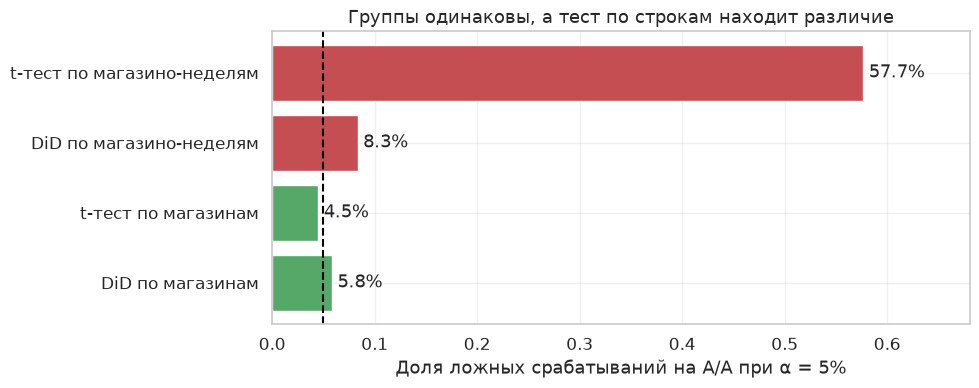

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [RED if v > 0.07 else (ORANGE if v > 0.06 else GREEN) for v in fpr.values[::-1]]
bars = ax.barh(fpr.index[::-1], fpr.values[::-1], color=colors)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in fpr.values[::-1]], padding=4)
ax.axvline(ALPHA, color='black', linestyle='--')
ax.set_xlim(0, fpr.max() * 1.18); ax.set_xlabel('Доля ложных срабатываний на A/A при α = 5%')
ax.set_title('Группы одинаковы, а тест по строкам находит различие')
plt.show()

Группы одинаковы по построению, а t-тест по магазино-неделям находит различие в **58%** A/A. Формула дизайн-эффекта предсказала это заранее: ICC 0.94 и 12 недель дают $DE = 11.3$ и 56% ложных срабатываний. 3 600 строк весят как ~320 независимых наблюдений, то есть почти одно на магазин.

Тесты по магазинам держат уровень: 4.5% и 5.8% (при 600 прогонах шум ±1.8 п.п.). DiD по магазино-неделям с ошибкой «строки независимы» — **8.3%**: он вычитает уровень магазина, но всё равно завышает. На реальных данных сети с автокоррелированными неделями этот же расчёт давал 16%; в нашей синтетике недельный шум независим, и завышение скромнее.

**Вопрос.** Почему DiD по магазино-неделям ошибается гораздо меньше, чем t-тест по ним же, но всё же больше 5%? Где он сломался бы сильнее?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

DiD вычитает уровень магазина, а именно он даёт ICC 0.94. После вычитания остаются недельный шум и тренды магазинов. Недельный шум в этой сети почти независим, поэтому формула «строки независимы» ошибается мало. Перекос даёт только то, что часть магазинов растёт быстрее остальных: это медленная компонента, она одинакова для всех недель магазина.

В реальных сетях недели одного магазина автокоррелированы: ремонт, конкурент открылся рядом, сменился директор. Там DiD по строкам срабатывает на A/A в 15–20% случаев (Bertrand, Duflo, Mullainathan, 2004). Правило одно: **единица анализа = единица рандомизации**. Недели помогают точнее посчитать число на магазин, но не умножают число магазинов.

</details>

## Задание 2. Мощность инъекцией эффекта (10 минут)

Формула MDE из встречи 2 считает наблюдения независимыми, а у нас они зависимы, и шум магазина устроен сложнее. Поэтому мощность считаем прямо по истории:

1. берём случайное окно и случайные группы магазинов, считаем DiD: $\Delta_i = \bar y_i^{\text{после}} - \bar y_i^{\text{до}}$, оценка — разность средних $\Delta_i$;
2. стандартное отклонение оценки по прогонам $\sigma_{\text{DiD}}$ даёт $\text{MDE} = (z_{1-\alpha/2} + z_{1-\beta})\,\sigma_{\text{DiD}}$;
3. для проверки **впрыскиваем** эффект в пилотную группу и смотрим, как часто t-тест по магазинам его находит.

Реализуйте:

* `did_sd(n_t, n_c, post, R, seed)` — $R$ раз: окно `random_window(rng, post=post)`, `n_t + n_c` случайных магазинов без повторов (`rng.choice`), первые `n_t` — пилот; $\Delta_i$ = среднее `HIST` за `post` недель минус среднее за `PRE` недель до них. Верните `np.std` разностей средних;
* `injected_power(lift, n_t, n_c, post, R, seed)` — то же, но прибавьте `lift` к $\Delta_i$ пилотных и верните долю $p < \alpha$ в `stats.ttest_ind`.

In [7]:
def did_sd(n_t: int, n_c: int, post: int = POST, R: int = 600, seed: int = SEED) -> float:
    # ВАШ КОД
    raise NotImplementedError


def injected_power(lift: float, n_t: int, n_c: int, post: int = POST, R: int = 600, seed: int = SEED) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [8]:
# @title Решение (нажмите, чтобы раскрыть)
def _did_deltas(rng, n_t, n_c, post):
    t0 = random_window(rng, post=post)
    idx = rng.choice(N_STORES, n_t + n_c, replace=False)
    delta = HIST[t0:t0 + post, idx].mean(axis=0) - HIST[t0 - PRE:t0, idx].mean(axis=0)
    return delta[:n_t], delta[n_t:]


def did_sd(n_t: int, n_c: int, post: int = POST, R: int = 600, seed: int = SEED) -> float:
    rng = np.random.default_rng(seed)
    effects = []
    for _ in range(R):
        a, b = _did_deltas(rng, n_t, n_c, post)
        effects.append(a.mean() - b.mean())
    return float(np.std(effects))


def injected_power(lift: float, n_t: int, n_c: int, post: int = POST, R: int = 600, seed: int = SEED) -> float:
    rng = np.random.default_rng(seed)
    hits = 0
    for _ in range(R):
        a, b = _did_deltas(rng, n_t, n_c, post)
        hits += stats.ttest_ind(a + lift, b).pvalue < ALPHA
    return hits / R

**Проверка.** Для 40 + 40 магазинов и 12 недель: без эффекта тест срабатывает в ~5%, на MDE — в ~80%.

In [9]:
# Проверка
sd_40 = did_sd(40, 40)
power_0 = injected_power(0.0, 40, 40)
power_mde = injected_power(Z_SUM * sd_40, 40, 40)
assert 0.0035 < sd_40 < 0.006, 'Разброс DiD для 40 + 40 магазинов и 12 недель около 0.5%'
assert 0.03 < power_0 < 0.075, 'Без эффекта доля срабатываний около 5%'
assert 0.72 < power_mde < 0.88, 'На MDE мощность около 80%'
print(f"40 + 40, 12 недель: σ_DiD = {sd_40:.2%}, MDE = {Z_SUM * sd_40:.2%}; A/A {power_0:.3f}, мощность на MDE {power_mde:.3f}")
print('Задание 2 принято')

40 + 40, 12 недель: σ_DiD = 0.48%, MDE = 1.34%; A/A 0.062, мощность на MDE 0.817
Задание 2 принято


Посчитаем MDE для разных размеров пилота и длительностей, а также для дизайна директора: 60 магазинов против 240.

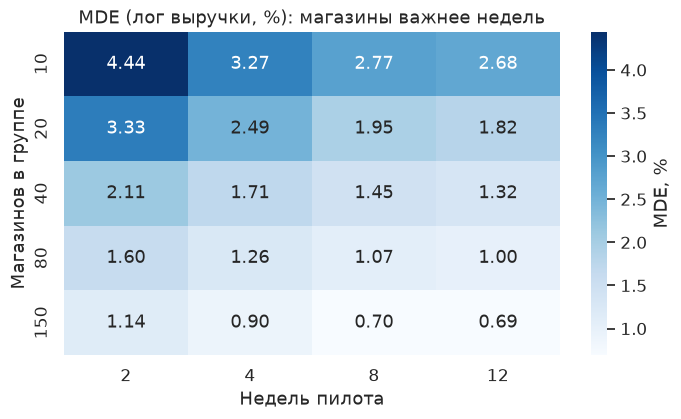

Недель пилота         2     4     8     12
Магазинов в группе                        
10                  4.44  3.27  2.77  2.68
20                  3.33  2.49  1.95  1.82
40                  2.11  1.71  1.45  1.32
80                  1.60  1.26  1.07  1.00
150                 1.14  0.90  0.70  0.69
Дизайн директора, 60 против 240, 12 недель: σ_DiD = 0.30%, MDE = 0.85%


In [10]:
ks, posts = (10, 20, 40, 80, 150), (2, 4, 8, 12)
mde = pd.DataFrame({post: {k: 100 * Z_SUM * did_sd(k, k, post, R=400) for k in ks} for post in posts})
mde.index.name, mde.columns.name = 'Магазинов в группе', 'Недель пилота'
sd_director = did_sd(60, 240)
mde_director = Z_SUM * sd_director

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(mde, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': 'MDE, %'}, ax=ax)
ax.set_title('MDE (лог выручки, %): магазины важнее недель')
plt.show()
print(mde.round(2).to_string())
print(f"Дизайн директора, 60 против 240, 12 недель: σ_DiD = {sd_director:.2%}, MDE = {mde_director:.2%}")

Что видно в таблице:

* **Магазины важнее недель.** Удвоение группы с 40 до 80 магазинов снижает MDE за 12 недель с 1.32% до 1.00%. Удлинение пилота с 8 до 12 недель при 40 магазинах — только с 1.45% до 1.32%.
* **После 8 недель MDE почти на полке.** Предпериод фиксирован (12 недель), его шум не усредняется. А у части магазинов свой тренд — медленная компонента, которая не усредняется, сколько ни жди.
* **Оговорка про синтетику.** В реальной сети полка наступает раньше, уже после 4 недель: там медленный дрейф магазинов сильнее. У нас недельный шум независим, поэтому недели помогают дольше. Такой расчёт делают заново на истории своей сети.

Дизайн директора — 60 магазинов против 240 за 12 недель: **MDE 0.85%**. Эффект в 4.5% он увидел бы с большим запасом.

**Вопрос.** Мощности у пилота директора хватает с запасом. Значит ли это, что его оценке можно верить?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет. Мощность и интервал описывают только **случайный** разброс: что будет, если выбирать магазины и даты случайно. Директор выбирал не случайно. Если отбор связан с динамикой выручки, оценка смещена, и смещение не уменьшается ни от числа магазинов, ни от длины пилота. Это проверяем в задании 3.

</details>

## Задание 3. Наивный DiD и плацебо по датам (10 минут)

Реализуйте `did_estimate(matrix, treated, control, t0, pre=PRE, post=POST)`:

* $\Delta_i$ = среднее `matrix` за недели `[t0, t0 + post)` минус среднее за `[t0 - pre, t0)`;
* `effect` — разность средних $\Delta_i$ пилота и контроля; `se` $= \sqrt{s_T^2/n_T + s_C^2/n_C}$ (дисперсии с `ddof=1`);
* верните словарь `effect`, `se`, `low`, `high` (интервал $\pm 1.96 \cdot se$).

Проверочная ячейка применит её к пилоту и к четырём **плацебо-окнам**: те же 12 + 12 недель, но целиком до старта, когда зоны не было. Если метод честный, плацебо дают около нуля.

In [11]:
def did_estimate(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int,
                 pre: int = PRE, post: int = POST) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [12]:
# @title Решение (нажмите, чтобы раскрыть)
def did_estimate(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int,
                 pre: int = PRE, post: int = POST) -> dict:
    delta = matrix[t0:t0 + post].mean(axis=0) - matrix[t0 - pre:t0].mean(axis=0)
    a, b = delta[treated], delta[control]
    effect = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return {'effect': effect, 'se': se, 'low': effect - 1.96 * se, 'high': effect + 1.96 * se}

In [13]:
# Проверка
PLACEBO_T0 = [16, 20, 24, 28]        # окна до старта: последнее заканчивается за неделю до пилота
naive = did_estimate(Y, pilot_idx, rest_idx, T0)
placebo = {t: did_estimate(Y, pilot_idx, rest_idx, t) for t in PLACEBO_T0}
assert abs(naive['effect'] - 0.056) < 0.003, 'Наивный DiD около +0.056 в логах'
assert naive['low'] > np.log(1 + BREAKEVEN), 'Наивная оценка выглядит как уверенная окупаемость'
assert all(p['low'] > 0 for p in placebo.values()), 'Плацебо до старта тоже показывают рост'


def fmt(est: dict) -> str:
    to_pct = lambda v: f"{np.expm1(v):+.2%}"
    return f"{to_pct(est['effect'])} [{to_pct(est['low'])}; {to_pct(est['high'])}]"


print(f"Пилот, наивный DiD: {fmt(naive)}")
for t, p in placebo.items():
    print(f"Плацебо с {WEEKS[t]:%d.%m.%Y}: {fmt(p)}")
print('Задание 3 принято')

Пилот, наивный DiD: +5.79% [+5.18%; +6.39%]
Плацебо с 22.04.2024: +2.12% [+1.55%; +2.68%]
Плацебо с 20.05.2024: +2.34% [+1.78%; +2.91%]
Плацебо с 17.06.2024: +2.34% [+1.81%; +2.87%]
Плацебо с 15.07.2024: +2.51% [+1.92%; +3.09%]
Задание 3 принято


Посмотрим, почему плацебо «находит» эффект там, где зоны не было. Ниже — разность средней лог-выручки пилотных магазинов и остальной сети по неделям.

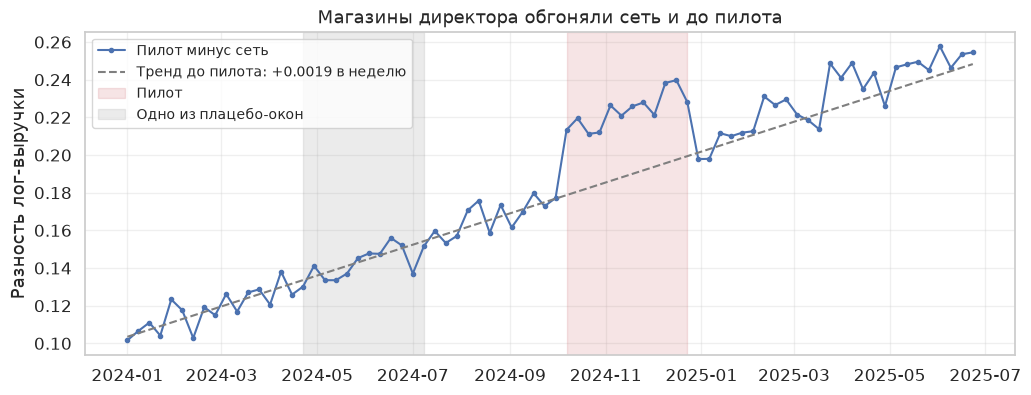

Отставание растёт на 0.0019 в неделю; между центрами окон «до» и «после» 12 недель → +0.023


In [14]:
gap = Y[:, pilot_idx].mean(axis=1) - Y[:, rest_idx].mean(axis=1)
weeks_num = np.arange(N_WEEKS)
slope, intercept = np.polyfit(weeks_num[:T0], gap[:T0], 1)

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(WEEKS, gap, color=BLUE, marker='o', markersize=3, label='Пилот минус сеть')
ax.plot(WEEKS, intercept + slope * weeks_num, color=GRAY, linestyle='--', label=f'Тренд до пилота: {slope:+.4f} в неделю')
ax.axvspan(WEEKS[T0], WEEKS[T0 + POST - 1], color=RED, alpha=0.15, label='Пилот')
ax.axvspan(WEEKS[PLACEBO_T0[0]], WEEKS[PLACEBO_T0[0] + POST - 1], color=GRAY, alpha=0.15, label='Одно из плацебо-окон')
ax.set_ylabel('Разность лог-выручки'); ax.legend(loc='upper left', fontsize=10)
ax.set_title('Магазины директора обгоняли сеть и до пилота')
plt.show()
print(f"Отставание растёт на {slope:.4f} в неделю; между центрами окон «до» и «после» 12 недель → {12 * slope:+.3f}")

Интервал у директора действительно узкий: **+5.8% [+5.2%; +6.4%]**, целиком выше точки окупаемости. Но все четыре плацебо-окна, когда зоны ещё не было, дают **+2.1…+2.5%** с такими же узкими интервалами.

Причина на графике. Магазины директора обгоняли сеть на 0.0019 лог-единиц в неделю ещё до пилота. Центры окон «до» и «после» разделяют 12 недель, это +0.023 — почти весь «эффект» плацебо. **Параллельные тренды нарушены**: «сильные» магазины директора просто растут быстрее.

Интервал ±0.6% честно описывает случайную ошибку и ничего не говорит о смещении. Смещение не уменьшается от роста выборки.

## Задание 4. Пары и DiD по парам (13 минут)

Первое, что приходит в голову: подобрать контроль получше. Каждому магазину директора подберём «близнеца» — магазин того же формата и региона с ближайшей выручкой до пилота — и посчитаем DiD по парам.

* `match_controls(level, treated, candidates, groups)`: для каждого пилотного магазина (в порядке `treated`) выберите среди **свободных** кандидатов той же группы (`groups[i] == groups[j]`) ближайшего по `level`; если в группе свободных не осталось — ближайшего среди всех свободных. Повторов быть не должно. Верните массив выбранных номеров столбцов.
* `pair_did(matrix, treated, matched, t0)`: $d_p = \Delta_{\text{пилот}} - \Delta_{\text{близнец}}$ для каждой пары; `effect` — среднее $d_p$, `se` — $s_d/\sqrt{n_{\text{пар}}}$. Верните словарь как в задании 3.

In [15]:
def match_controls(level: np.ndarray, treated: np.ndarray, candidates: np.ndarray, groups: np.ndarray) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError


def pair_did(matrix: np.ndarray, treated: np.ndarray, matched: np.ndarray, t0: int,
             pre: int = PRE, post: int = POST) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [16]:
# @title Решение (нажмите, чтобы раскрыть)
def match_controls(level: np.ndarray, treated: np.ndarray, candidates: np.ndarray, groups: np.ndarray) -> np.ndarray:
    free = set(candidates.tolist())
    chosen = []
    for i in treated:
        pool = [j for j in free if groups[j] == groups[i]] or list(free)
        j = min(pool, key=lambda c: abs(level[c] - level[i]))
        free.remove(j)
        chosen.append(j)
    return np.array(chosen)


def pair_did(matrix: np.ndarray, treated: np.ndarray, matched: np.ndarray, t0: int,
             pre: int = PRE, post: int = POST) -> dict:
    delta = matrix[t0:t0 + post].mean(axis=0) - matrix[t0 - pre:t0].mean(axis=0)
    d = delta[treated] - delta[matched]
    effect, se = d.mean(), d.std(ddof=1) / np.sqrt(len(d))
    return {'effect': effect, 'se': se, 'low': effect - 1.96 * se, 'high': effect + 1.96 * se}

In [17]:
# Проверка
level_pre = Y[T0 - PRE:T0].mean(axis=0)
groups = (info['format'] + '/' + info['region']).to_numpy()
matched = match_controls(level_pre, pilot_idx, rest_idx, groups)
assert len(set(matched)) == len(pilot_idx) and not set(matched) & set(pilot_idx), 'Близнецы без повторов и не из пилота'
same_group = (groups[matched] == groups[pilot_idx]).mean()
assert same_group > 0.9, 'Почти всем находится близнец той же группы'
pairs = pair_did(Y, pilot_idx, matched, T0)
pairs_placebo = {t: pair_did(Y, pilot_idx, matched, t) for t in PLACEBO_T0}
assert pairs['low'] > np.log(1 + BREAKEVEN), 'Пары почти не меняют оценку'
assert all(p['low'] > 0 for p in pairs_placebo.values()), 'И плацебо по парам остаются положительными'
print(f"Близнецов той же группы: {same_group:.0%}; разница уровня в паре: {np.abs(level_pre[pilot_idx] - level_pre[matched]).mean():.3f} лог")
print(f"DiD по парам: {fmt(pairs)}")
print('Плацебо по парам: ' + ', '.join(fmt(p) for p in pairs_placebo.values()))
print('Задание 4 принято')

Близнецов той же группы: 100%; разница уровня в паре: 0.058 лог
DiD по парам: +5.90% [+5.20%; +6.60%]
Плацебо по парам: +2.27% [+1.51%; +3.05%], +2.62% [+1.92%; +3.32%], +2.41% [+1.78%; +3.04%], +2.50% [+1.77%; +3.24%]
Задание 4 принято


Пары выровняли уровень, формат и регион, но оценка почти не сдвинулась, и плацебо по-прежнему положительные. Матчинг выравнивает то, что видно в предпериоде **на уровне**, а причина смещения — **скорость роста**. Ни у одного магазина остальной сети нет такого же ускоренного роста, поэтому никакой близнец его не повторит.

Что делать, если отбор уже случился? Использовать то, что тренд виден **в истории**: для каждого магазина провести линию по всем неделям до окна, продолжить её на окно и сравнить факт с продолжением. Для пары — то же по разности «пилот минус близнец». Это DiD с поправкой на тренд пары. Проверяем его тем же плацебо.

In [18]:
def trend_residual(matrix: np.ndarray, t0: int, post: int = POST, start: int = 0) -> np.ndarray:
    # Средний остаток магазина за окно относительно своей линии тренда по неделям [start, t0)
    t = np.arange(len(matrix))
    X = np.c_[np.ones(t0 - start), t[start:t0]]
    beta = np.linalg.lstsq(X, matrix[start:t0], rcond=None)[0]
    forecast = np.c_[np.ones(post), t[t0:t0 + post]] @ beta
    return (matrix[t0:t0 + post] - forecast).mean(axis=0)


def pair_trend_did(matrix, treated, matched, t0, post=POST):
    r = trend_residual(matrix, t0, post)
    d = r[treated] - r[matched]
    effect, se = d.mean(), d.std(ddof=1) / np.sqrt(len(d))
    return {'effect': effect, 'se': se, 'low': effect - 1.96 * se, 'high': effect + 1.96 * se}


trend = pair_trend_did(Y, pilot_idx, matched, T0)
trend_placebo = {t: pair_trend_did(Y, pilot_idx, matched, t) for t in PLACEBO_T0}
assert all(abs(p['effect']) < 0.01 for p in trend_placebo.values()), 'Плацебо с поправкой на тренд около нуля'

rows = {'Наивный DiD, вся сеть': (naive, placebo), 'DiD по парам': (pairs, pairs_placebo),
        'Пары + поправка на тренд': (trend, trend_placebo)}
summary = pd.DataFrame({name: {'Пилот, %': round(100 * np.expm1(est['effect']), 2),
                               'ДИ, %': f"[{100 * np.expm1(est['low']):+.1f}; {100 * np.expm1(est['high']):+.1f}]",
                               'Плацебо, среднее %': round(100 * np.expm1(np.mean([p['effect'] for p in pl.values()])), 2),
                               'Плацебо, max |·| %': round(100 * max(abs(np.expm1(p['effect'])) for p in pl.values()), 2)}
                        for name, (est, pl) in rows.items()}).T
summary

,"Пилот, %","ДИ, %","Плацебо, среднее %","Плацебо, max |·| %"
"Наивный DiD, вся сеть",5.79,[+5.2; +6.4],2.33,2.51
DiD по парам,5.9,[+5.2; +6.6],2.45,2.62
Пары + поправка на тренд,3.56,[+2.8; +4.4],0.34,0.54


* **Пары по формату, региону и уровню** не помогли: +5.9%, плацебо в среднем +2.45%. Близнец похож на пилотный магазин уровнем (разница 0.058 лог), но растёт как вся сеть.
* **Поправка на тренд пары** даёт **+3.56% [+2.8%; +4.4%]**, а плацебо — в пределах ±0.54%. Интервал шире, чем у наивного DiD: продолжение линии на 12 недель вперёд добавляет шум. Зато метод прошёл проверку.
* **Решение.** Верхняя граница 4.4% ниже точки окупаемости 4.5%. Зона, скорее всего, не окупается, хотя эффект есть и он положительный.

**Вопрос.** Поправка на тренд прошла плацебо. Можно ли теперь считать её «как A/B»? Что ещё может пойти не так?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нельзя: это модель, а не рандомизация. Поправка честна, пока тренд линейный и продолжается так же в окне пилота. Её ломают:

* **излом тренда** ровно в окне (директор выбрал магазины, у которых рост ещё и ускоряется);
* **возврат к среднему**: если выбирали «тех, кто вырос за последний месяц», линия по истории переоценит будущее;
* **сезон, разный у групп**: тренд его не вычтет, нужна годовая база (для этого нужна история хотя бы за год до пилота, у нас её нет);
* **экстраполяция на 12+ недель** увеличивает ошибку: интервал у поправки шире, чем у наивного DiD.

Плацебо проверяет только то, что метод не находит эффект там, где его не было, **в прошлом**. Поэтому вывод формулируют осторожно: «эффект около 3.5%, ниже точки окупаемости; уверенность ограничена допущением о тренде». Следующий пилот — рандомизация внутри пар.

</details>

### Сверка с истиной (только для разбора)

Данные синтетические, поэтому истинный эффект известен. Файл `store_panel_truth.csv` участникам не нужен для решения: смотрим в него только сейчас, после всех оценок.

In [19]:
truth = pd.read_csv('../data/store_panel_truth.csv').set_index('store').loc[STORES]
assert set(truth.index[truth['treated'] == 1]) == set(PILOT_STORES), 'Список директора совпадает с истинным списком'
true_lift = truth.loc[truth['treated'] == 1, 'true_sales_lift'].iloc[0]
check = summary[['Пилот, %']].copy()
check['Ошибка, п.п.'] = (check['Пилот, %'] - 100 * true_lift).round(2)
check['Окупается (≥ 4.5%)?'] = np.where(check['Пилот, %'] >= 100 * BREAKEVEN, 'да', 'нет')
print(f"Истинный эффект на выручку: {true_lift:+.2%} (трафик {truth['true_traffic_lift'].max():+.1%}, чек {truth['true_check_lift'].max():+.1%})")
check

Истинный эффект на выручку: +3.53% (трафик +1.5%, чек +2.0%)


,"Пилот, %","Ошибка, п.п.",Окупается (≥ 4.5%)?
"Наивный DiD, вся сеть",5.79,2.26,да
DiD по парам,5.9,2.37,да
Пары + поправка на тренд,3.56,0.03,нет


Истинный эффект — **+3.53%**. Наивный DiD и DiD по парам ошиблись на 2.3–2.4 п.п. Это почти втрое больше MDE пилота, и этого хватило, чтобы перевернуть решение: «окупается» вместо «не окупается».

Поправка на тренд ошиблась на 0.03 п.п. Здесь есть доля везения: в синтетике дополнительный рост пилотных магазинов строго линейный, ровно как допускает метод. В реальной сети на это рассчитывать нельзя. Плацебо — необходимая проверка, но не достаточная. Лучшее лечение — следующая волна со случайным выбором внутри пар.

## Задание 5. Switchback: окно и A/A по эпохам (10 минут)

Другая гипотеза сети: новый алгоритм назначения курьеров для доставки из магазинов. Курьеры в зоне общие, поэтому A/B по заказам ломает SUTVA: тестовые заказы забирают курьеров у контрольных. Рандомизируем **зону × окно времени**: всё окно зоны целиком в тесте или в контроле.

Симулятор ниже: 20 зон, 4 недели почасовых данных, у зон разный уровень, есть суточный цикл, шум автокоррелирован (AR 0.9: соседние часы похожи). Эффект +1.0 заказа в час, но набирается не сразу: курьерам нужно **2 часа**, чтобы перераспределиться (carryover). После переключения первые 2 часа окна — смесь режимов.

Реализуйте `switchback_estimate(outcome, schedule, window, burn)`:

1. вычтите суточный цикл: среднее по всем зонам и дням для каждого часа суток (`outcome.reshape(n_zones, -1, 24).mean(axis=(0, 1))`, растянутое `np.tile` на все дни);
2. разбейте ряд каждой зоны на окна длиной `window`, **отбросьте первые `burn` часов** каждого окна, усредните остаток — это значение эпохи;
3. в каждой зоне: среднее тестовых эпох минус среднее контрольных; зоны, где нет одной из групп, пропустите;
4. эффект — среднее этих разностей по зонам, `se` — их $s/\sqrt{n}$, `pvalue` — `stats.ttest_1samp(d, 0)`. Верните `(effect, se, pvalue)`.

Зона сама себе контроль, поэтому её уровень сокращается.

In [20]:
N_ZONES, N_HOURS, SB_EFFECT, CARRYOVER = 20, 24 * 28, 1.0, 2


def make_schedule(window: int, rng, n_zones: int = N_ZONES, n_hours: int = N_HOURS) -> np.ndarray:
    # Зона × час: внутри окна длиной window режим не меняется
    return np.repeat(rng.integers(0, 2, size=(n_zones, n_hours // window)), window, axis=1)


def simulate_zones(schedule: np.ndarray, effect: float, rng, carryover: int = CARRYOVER, ar: float = 0.9) -> np.ndarray:
    n_zones, n_hours = schedule.shape
    daily = 4 * np.sin(2 * np.pi * np.arange(n_hours) / 24)
    level = rng.normal(0, 3, (n_zones, 1))
    shocks = rng.normal(0, 1, (n_zones, n_hours))
    shocks[:, 0] /= np.sqrt(1 - ar ** 2)
    noise = lfilter([1], [1, -ar], shocks, axis=1)
    exposure = lfilter(np.ones(carryover + 1) / (carryover + 1), [1], schedule.astype(float), axis=1)
    return 20 + level + daily + noise + effect * exposure

In [21]:
def switchback_estimate(outcome: np.ndarray, schedule: np.ndarray, window: int, burn: int = 0) -> tuple:
    # ВАШ КОД
    raise NotImplementedError

In [22]:
# @title Решение (нажмите, чтобы раскрыть)
def switchback_estimate(outcome: np.ndarray, schedule: np.ndarray, window: int, burn: int = 0) -> tuple:
    n_zones, n_hours = outcome.shape
    hour_of_day = outcome.reshape(n_zones, -1, 24).mean(axis=(0, 1))
    y = outcome - np.tile(hour_of_day, n_hours // 24)
    epochs = y.reshape(n_zones, n_hours // window, window)[:, :, burn:].mean(axis=2)
    arm = schedule[:, ::window]
    with np.errstate(invalid='ignore', divide='ignore'):
        diff = (epochs * arm).sum(axis=1) / arm.sum(axis=1) - (epochs * (1 - arm)).sum(axis=1) / (1 - arm).sum(axis=1)
    d = diff[np.isfinite(diff)]
    return d.mean(), d.std(ddof=1) / np.sqrt(len(d)), stats.ttest_1samp(d, 0).pvalue

**Проверка.** Сравним окна от 1 до 96 часов: без отбрасывания и с отбрасыванием 2 часов после начала окна. Затем A/A: обычный t-тест по зона-часам против вашего теста по эпохам.

In [23]:
# Проверка
WINDOWS = [1, 2, 3, 4, 6, 8, 12, 24, 48, 96]


def window_study(R: int = 120, seed: int = SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    rows = []
    for window in WINDOWS:
        estimates = {0: [], CARRYOVER: []}
        for _ in range(R):
            schedule = make_schedule(window, rng)
            outcome = simulate_zones(schedule, SB_EFFECT, rng)
            for burn in estimates:
                if burn < window:
                    estimates[burn].append(switchback_estimate(outcome, schedule, window, burn)[0])
        for burn, values in estimates.items():
            if values:
                v = np.array(values)
                rows.append({'Окно, ч': window, 'Отбрасываем, ч': burn, 'Смещение': v.mean() - SB_EFFECT,
                             'Разброс': v.std(), 'RMSE': np.sqrt(((v - SB_EFFECT) ** 2).mean())})
    return pd.DataFrame(rows)


def sb_aa(windows=(1, 3, 6, 12, 24), R: int = 200, seed: int = SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    out = {}
    for window in windows:
        hourly, epoch = [], []
        for _ in range(R):
            schedule = make_schedule(window, rng)
            outcome = simulate_zones(schedule, 0.0, rng)
            hourly.append(stats.ttest_ind(outcome[schedule == 1], outcome[schedule == 0]).pvalue < ALPHA)
            epoch.append(switchback_estimate(outcome, schedule, window)[2] < ALPHA)
        out[window] = {'t-тест по зона-часам': np.mean(hourly), 'Тест по эпохам': np.mean(epoch)}
    return pd.DataFrame(out).T.rename_axis('Окно, ч')


study = window_study()
aa_sb = sb_aa()
burned = study[study['Отбрасываем, ч'] == CARRYOVER].set_index('Окно, ч')
raw = study[study['Отбрасываем, ч'] == 0].set_index('Окно, ч')
best_window = int(burned['RMSE'].idxmin())
assert raw.loc[1, 'Смещение'] < -0.5, 'Окно 1 час без отбрасывания сильно занижает эффект'
assert burned['Смещение'].abs().max() < 0.05, 'С отбрасыванием 2 часов смещение исчезает'
assert burned.loc[96, 'Разброс'] > 1.5 * burned.loc[4, 'Разброс'], 'Длинное окно — меньше эпох и больше разброс'
assert 3 <= best_window <= 12, 'Оптимальное окно — несколько длительностей переноса'
assert (aa_sb['Тест по эпохам'].between(0.015, 0.095)).all(), 'Тест по эпохам держит 5%'
assert aa_sb.loc[12, 't-тест по зона-часам'] > 0.3, 't-тест по часам сильно завышает ошибку'
print(f"Лучшее окно по RMSE (с отбрасыванием {CARRYOVER} ч): {best_window} ч")
print('Задание 5 принято')

Лучшее окно по RMSE (с отбрасыванием 2 ч): 3 ч
Задание 5 принято


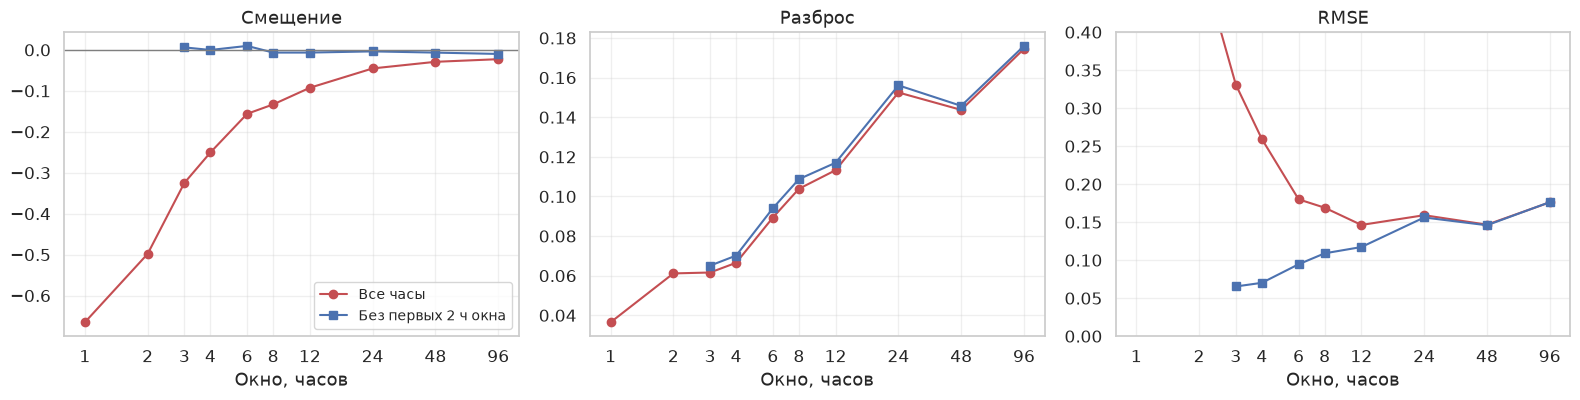

Смещение        Разброс          RMSE       
Отбрасываем, ч        0      2       0      2      0      2
Окно, ч                                                    
1                -0.665    NaN   0.036    NaN  0.666    NaN
2                -0.498    NaN   0.061    NaN  0.502    NaN
3                -0.325  0.006   0.062  0.065  0.331  0.065
4                -0.251 -0.000   0.066  0.070  0.259  0.070
6                -0.156  0.010   0.089  0.094  0.180  0.095
8                -0.133 -0.007   0.104  0.109  0.169  0.109
12               -0.093 -0.007   0.113  0.117  0.146  0.117
24               -0.045 -0.004   0.152  0.156  0.159  0.156
48               -0.029 -0.007   0.144  0.146  0.147  0.146
96               -0.023 -0.010   0.174  0.176  0.176  0.176

,t-тест по зона-часам,Тест по эпохам
"Окно, ч",,
1,0.040,0.025
3,0.240,0.050
6,0.445,0.055
12,0.485,0.060
24,0.655,0.080


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, metric in zip(axes, ['Смещение', 'Разброс', 'RMSE']):
    ax.plot(raw.index, raw[metric], 'o-', color=RED, label='Все часы')
    ax.plot(burned.index, burned[metric], 's-', color=BLUE, label=f'Без первых {CARRYOVER} ч окна')
    ax.set_xscale('log', base=2); ax.set_xticks(WINDOWS, WINDOWS); ax.minorticks_off()
    ax.set_xlabel('Окно, часов'); ax.set_title(metric)
axes[0].axhline(0, color=GRAY, linewidth=1); axes[0].legend(fontsize=10)
axes[2].set_ylim(0, 0.4)
plt.tight_layout(); plt.show()
display(study.pivot(index='Окно, ч', columns='Отбрасываем, ч', values=['Смещение', 'Разброс', 'RMSE']).round(3))
display(aa_sb.round(3))

* **Без отбрасывания короткие окна занижают эффект.** Окно 1 час теряет две трети эффекта (−0.67), окно 3 часа — треть (−0.33). Это формула из теории: $-\tau\,m/(2w)$.
* **Отбрасывание первых 2 часов окна** убирает смещение при любом окне от 3 часов. Остаётся разброс, и он растёт с окном: 0.065 при 3 часах, 0.18 при 96 часах. Эпох становится меньше, а соседние часы похожи.
* **Минимум RMSE — окно 3 часа,** но кривая пологая до 6 часов (0.095). Длительность переноса на практике известна неточно. Если перенос на деле 3 часа, окно 3 часа с burn-in 2 часа уже смещено. Поэтому окно берут с запасом: в 3–4 раза длиннее ожидаемого переноса.
* **A/A.** t-тест по зона-часам срабатывает в 24–66% случаев при окнах 3–24 часа. Тест по эпохам держит 2.5–8% (200 прогонов, шум ±3 п.п.).

**Вопрос.** Почему t-тест по зона-часам ошибается тем сильнее, чем длиннее окно, хотя данных столько же?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Часы внутри окна получают одно и то же назначение и похожи между собой (AR-шум, уровень зоны). Окно — это кластер, и его эффект дизайна $1 + (m-1)\rho$ растёт с размером окна $m$. При окне 1 час кластер — один час, и наивный тест почти честен. Дальше независимых назначений всё меньше, а t-тест по часам продолжает считать их тысячами. Тест по эпохам знает, сколько на самом деле было рандомизаций.

</details>

## Итог: карта «ограничение → дизайн»

Что получилось на кейсе сети:

* **Единица.** ICC 0.94: 12 недель магазина весят как одно наблюдение, а t-тест по магазино-неделям ошибается на A/A в 58% случаев. Тест — по магазинам.
* **Мощность.** MDE считаем инъекцией по истории. Его покупают магазины, а не недели. У пилота директора MDE 0.85%, так что дело не в шуме.
* **Смещение.** Наивный DiD даёт +5.8%, плацебо до старта — +2.3%. Пары по уровню этого не лечат (+5.9%). Поправка на тренд даёт +3.6%, плацебо около нуля, истина — +3.53%. Зона не окупается.
* **Switchback.** При переносе 2 часа отбрасываем начало каждого окна. Окно — 3–6 часов, тест — по эпохам.

Артефакт встречи — карта `design_map.md` в папке встречи: таблица «ограничение → дизайн → что проверить → ловушка». Заполните строки своими примерами из практики команды; строки этого кейса — кластерный A/B, пилот с парами + DiD и switchback — уже содержат числа отсюда.

In [25]:
CASE_FOR_MAP = {
    'icc': round(float(rho), 2),
    'design_effect_12w': round(float(design_effect), 1),
    'aa_fpr_store_weeks': round(float(fpr['t-тест по магазино-неделям']), 2),
    'mde_director_pct': round(100 * float(mde_director), 2),
    'naive_did_pct': round(100 * float(np.expm1(naive['effect'])), 2),
    'placebo_mean_pct': round(100 * float(np.expm1(np.mean([p['effect'] for p in placebo.values()]))), 2),
    'pairs_did_pct': round(100 * float(np.expm1(pairs['effect'])), 2),
    'trend_did_pct': round(100 * float(np.expm1(trend['effect'])), 2),
    'pays_off': bool(np.expm1(trend['high']) >= BREAKEVEN),
    'switchback_window_h': best_window,
}
CASE_FOR_MAP

{'icc': 0.94,
 'design_effect_12w': 11.3,
 'aa_fpr_store_weeks': 0.58,
 'mde_director_pct': 0.85,
 'naive_did_pct': 5.79,
 'placebo_mean_pct': 2.33,
 'pairs_did_pct': 5.9,
 'trend_did_pct': 3.56,
 'pays_off': False,
 'switchback_window_h': 3}

## Дополнительные задания

### Д1. Трафик и чек

Выручка = трафик × средний чек. Разложите эффект: примените `pair_trend_did` к логарифму трафика и к логарифму чека (`sales / traffic`). Сумма двух эффектов в логах равна эффекту на выручку. Что из двух директор мог бы проверить дешевле, без кассовых данных?

In [26]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [27]:
# @title Решение (нажмите, чтобы раскрыть)
traffic = np.log(panel.pivot(index='week', columns='store', values='traffic')).to_numpy()
check_log = Y - traffic
effect_traffic = pair_trend_did(traffic, pilot_idx, matched, T0)
effect_check = pair_trend_did(check_log, pilot_idx, matched, T0)
print(f"Трафик: {fmt(effect_traffic)}; чек: {fmt(effect_check)}")
print(f"Сумма в логах: {effect_traffic['effect'] + effect_check['effect']:.4f}, выручка: {trend['effect']:.4f}")

Трафик: +1.37% [+0.60%; +2.15%]; чек: +2.16% [+1.78%; +2.54%]
Сумма в логах: 0.0350, выручка: 0.0350


In [28]:
# Проверка
assert abs(effect_traffic['effect'] + effect_check['effect'] - trend['effect']) < 1e-9
assert 0.005 < effect_traffic['effect'] < 0.025 and 0.01 < effect_check['effect'] < 0.03
print('Д1 принято')

Д1 принято


### Д2. Синтетический контроль

Синтетический контроль подбирает неотрицательные веса магазинов сети (сумма 1), чтобы взвешенная смесь повторила **кривую** пилотной группы до старта. Это стандартный инструмент, когда рандомизация невозможна. Проверьте, справится ли он здесь.

Синтетический контроль: +7.77%, доноров с весом: 22
Плацебо: +2.76%, +3.33%, +4.00%, +3.99%


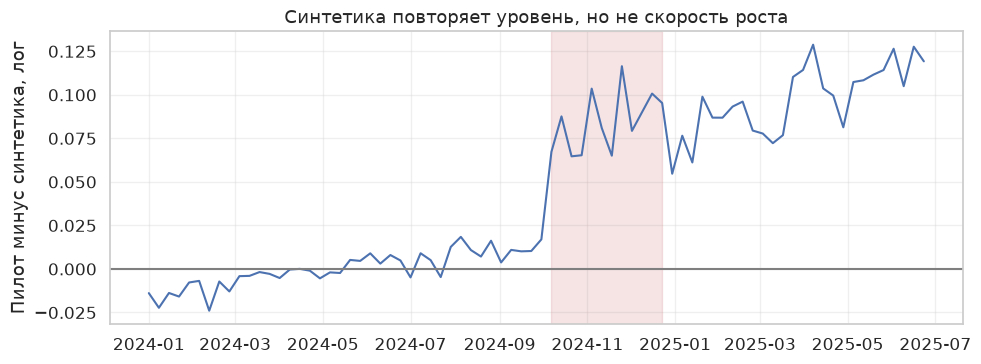

In [29]:
def synth_effect(matrix, treated, candidates, t0, post=POST, start=0):
    target = matrix[start:t0, treated].mean(axis=1)
    A = np.r_[matrix[start:t0, candidates], 100 * np.ones((1, len(candidates)))]
    w = nnls(A, np.r_[target, 100])[0]
    w = w / w.sum()
    synth = matrix[:, candidates] @ w
    gap_synth = matrix[:, treated].mean(axis=1) - synth
    return gap_synth, gap_synth[t0:t0 + post].mean() - gap_synth[t0 - PRE:t0].mean(), (w > 1e-3).sum()


gap_synth, sc_effect, n_donors = synth_effect(Y, pilot_idx, rest_idx, T0)
sc_placebo = [synth_effect(Y, pilot_idx, rest_idx, t)[1] for t in PLACEBO_T0]
print(f"Синтетический контроль: {np.expm1(sc_effect):+.2%}, доноров с весом: {n_donors}")
print('Плацебо: ' + ', '.join(f"{np.expm1(v):+.2%}" for v in sc_placebo))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(WEEKS, gap_synth, color=BLUE)
ax.axvspan(WEEKS[T0], WEEKS[T0 + POST - 1], color=RED, alpha=0.15)
ax.axhline(0, color=GRAY); ax.set_ylabel('Пилот минус синтетика, лог')
ax.set_title('Синтетика повторяет уровень, но не скорость роста')
plt.show()

**Вопрос.** Почему синтетический контроль не убрал смещение, хотя «подгонял кривую»?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Смесь с неотрицательными весами живёт внутри **выпуклой оболочки** доноров: она не может расти быстрее самого быстрого из них. В нашей сети нет магазинов с таким же ускоренным ростом, как у выбранных директором. Синтетика проходит через середину пилотной кривой до старта, а дальше отстаёт, и разрыв снова приписывается пилоту.

Перед синтетическим контролем проверяют, что пилот лежит внутри облака доноров по уровню **и динамике**, и прогоняют плацебо по датам и по донорам (каждый донор по очереди в роли «пилота»).

</details>

### Д3. Если бы рандомизировали

Директор согласился на вторую волну: 60 магазинов, **случайно внутри пар**. Оцените на истории до пилота (`HIST`) разброс четырёх дизайнов для 30 + 30 магазинов: только пилот (разность средних за 12 недель), пары по уровню, DiD, пары + DiD. Пары стройте `match_controls` по уровню до старта внутри формата, а знак в паре выбирайте монеткой. Что даёт основное снижение разброса и что добавляют пары поверх DiD?

In [30]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [31]:
# @title Решение (нажмите, чтобы раскрыть)
def design_spread(k: int = 30, R: int = 400, seed: int = SEED) -> pd.Series:
    rng = np.random.default_rng(seed)
    fmt_groups = info['format'].to_numpy()
    out = {name: [] for name in ('Только пилот', 'Пары по уровню', 'DiD', 'Пары + DiD')}
    for _ in range(R):
        t0 = random_window(rng)
        idx = rng.choice(N_STORES, 2 * k, replace=False)
        after, before = HIST[t0:t0 + POST].mean(axis=0), HIST[t0 - PRE:t0].mean(axis=0)
        delta = after - before
        t, c = idx[:k], idx[k:]
        out['Только пилот'].append(after[t].mean() - after[c].mean())
        out['DiD'].append(delta[t].mean() - delta[c].mean())
        first = idx[:k]
        second = match_controls(before, first, idx[k:], fmt_groups)
        signs = rng.choice([-1, 1], k)
        out['Пары по уровню'].append((signs * (after[first] - after[second])).mean())
        out['Пары + DiD'].append((signs * (delta[first] - delta[second])).mean())
    return 100 * pd.Series({name: np.std(v) for name, v in out.items()})


spread = design_spread()
spread.round(2).to_frame('Разброс оценки, %')

,"Разброс оценки, %"
Только пилот,9.57
Пары по уровню,6.14
DiD,0.55
Пары + DiD,0.52


Ожидаемый ответ: основное снижение разброса даёт учёт предпериода (DiD): магазины различаются уровнем намного сильнее, чем меняются во времени (ICC 0.94). Пары поверх DiD добавляют мало, зато страхуют от неудачного разбиения при малом числе магазинов и дают понятный бизнесу анализ «каждому пилотному — свой контрольный». И главное: при случайном знаке в паре смещения от отбора нет вообще.

### Д4. Перенос на сеть

60 магазинов директора — на 63% формата «a». Если эффект зоны зависит от формата, среднее по пилоту не равно эффекту на всю сеть. Как бы вы перевзвесили оценку на структуру сети и что для этого нужно в дизайне следующей волны?